# sctranscriptogramer — system-level differential expression in microglia

This notebook runs the full **sctranscriptogramer** workflow on a minimal real dataset:
microglia from the **ROSMAP_MIT** batch of the Garg et al. microglial atlas.

**Question:** which functional *systems* (contiguous regions of the STRING-ordered proteome) shift
between **late-AD and non-AD** microglia, resolved **per cell state**?

**Pipeline**

1. Load the prepared AnnData (raw RNA counts + metadata)
2. Map gene symbols → ENSEMBL peptide IDs (the ordering's id space)
3. Aggregate cells into **group-pure metacells** (metacells2), never mixing status / cell-state / donor
4. Project metacells onto the fixed protein **ordering**
5. Compute the **transcriptogram** (sliding-window smoothing) → embedding + window pseudo-counts
6. **Differential systems**: late-AD vs non-AD per cell state (NB mixed model, donor random effect)
7. **GO enrichment** of the resulting clusters
8. Visualisation: difference-of-means and GO-term-rate along the ordering

In [1]:
%matplotlib inline
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc

import sctranscriptogramer as sctg
import sctranscriptogramer.pl as pl

warnings.simplefilter("ignore")
sc.settings.verbosity = 0

OBJ = Path("/dora_zfs/home/deso14_OSUMC/projects/sctranscriptogram/testing/objects")
RES = Path("/dora_zfs/home/deso14_OSUMC/projects/sctranscriptogram/testing/results")
RES.mkdir(exist_ok=True)
print("sctranscriptogramer", sctg.__version__)

sctranscriptogramer 0.0.1.dev0


## 1. Load the data

The object was prepared from the Seurat `.qs` (ROSMAP_MIT microglia): raw RNA **counts** in `X` and
`layers['counts']`, with tidy metadata columns `status` (`ADdiag3types`), `cell_state`
(`Integrated_cell_type`) and `donor` (`Sample.ID`).

In [2]:
adata = ad.read_h5ad(OBJ / "rosmap_mit_microglia.h5ad")
print(adata)
display(adata.obs[["status", "cell_state", "donor"]].head())

AnnData object with n_obs × n_vars = 4500 × 37856
    obs: 'batch', 'Sample.ID', 'ADdiag3types', 'Integrated_cell_type', 'Cell_type', 'Status', 'Gender', 'msex', 'age_death', 'PMI', 'pmi', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'donor', 'status', 'cell_state'
    layers: 'counts'


,status,cell_state,donor
barcode,,,
SM_190312Tsa.AACGTTGAGCGTGAGT-17,nonAD,MHCII,ROSMAP-77461
SM_190312Tsa.ACGATACGTAGGCTGA-17,nonAD,Inflammatory_I,ROSMAP-77461
SM_190312Tsa.CACAGGCCATGTTCCC-17,nonAD,Inflammatory_II,ROSMAP-77461
SM_190312Tsa.CACCAGGCATAGGATA-17,nonAD,MHCII,ROSMAP-77461
SM_190312Tsa.CACTCCATCTGGTATG-17,nonAD,Activated,ROSMAP-77461


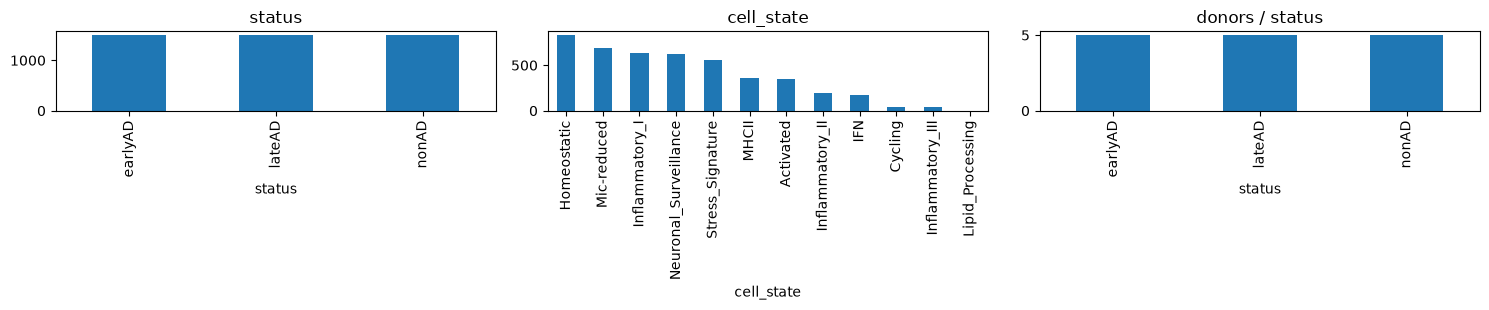

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
adata.obs["status"].value_counts().plot.bar(ax=axes[0], title="status")
adata.obs["cell_state"].value_counts().plot.bar(ax=axes[1], title="cell_state")
adata.obs.groupby("status", observed=True)["donor"].nunique().plot.bar(ax=axes[2], title="donors / status")
for a in axes:
    a.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

## 2. Define the contrast and focus states

We contrast **late-AD (case)** vs **non-AD (control)** and, for a fast minimal run, keep the
best-populated microglial states. earlyAD is left out of the two-group contrast.

In [4]:
CASE, CONTROL = "lateAD", "nonAD"
KEEP_STATES = ["Homeostatic", "Inflammatory_I", "Mic-reduced",
               "Neuronal_Surveillance", "Stress_Signature"]

sub = adata[adata.obs["status"].isin([CASE, CONTROL])
            & adata.obs["cell_state"].isin(KEEP_STATES)].copy()
print("subset:", sub.shape)
sub.obs.groupby(["cell_state", "status"], observed=True).size().unstack()

subset: (2201, 37856)


status,lateAD,nonAD
cell_state,,
Homeostatic,316,215
Inflammatory_I,127,267
Mic-reduced,262,278
Neuronal_Surveillance,269,168
Stress_Signature,93,206


## 3. Map gene symbols → ENSEMBL peptide IDs

The ordering is keyed by ENSEMBL peptide IDs, but the matrix uses gene **symbols**. `map_to_protein`
returns a `(protein, identifier)` dictionary (cached to parquet) that `project_to_ordering` consumes.

In [5]:
dictionary = sctg.map_to_protein(
    sub.var_names, id_type="symbol", species="human",
    cache_path=OBJ / "symbol2ensp.parquet",
)
print("mapped symbols:", dictionary["identifier"].nunique(),
      "| (symbol, ENSP) pairs:", len(dictionary))
dictionary.head()

mapped symbols: 19106 | (symbol, ENSP) pairs: 237884


,protein,identifier
0,ENSP00000493376,OR4F5
1,ENSP00000409316,OR4F29
2,ENSP00000329982,OR4F16
3,ENSP00000342313,SAMD11
4,ENSP00000349216,SAMD11


## 4. Aggregate into group-pure metacells

Cells are partitioned by `status × cell_state × donor` **before** metacells are built, so no metacell
ever mixes conditions, cell states, or donors — the latter is what lets the differential model use
**donor as a random effect**.

The embedding (`X`) is normalized with **`tmm_log2cpm`** (the default): edgeR-style `log2(CPM + prior)`
on **TMM effective library sizes** — a composition-robust scale for the embedding (UMAP / clustering).

In [6]:
mc = sctg.pp.aggregate_metacells(
    sub,
    group_keys=["status", "cell_state", "donor"],
    engine="metacells2",
    counts_layer="counts",
    carry_obs=["msex", "age_death", "percent.mt"],  # carried for use as model covariates
    engine_kwargs={"target_metacell_size": 20},
)
print("metacells:", mc.shape)
mc.obs.groupby(["cell_state", "status"], observed=True).size().unstack()

set partition.var[lateral_gene]: 0 true (0%) out of 37856 bools


set partition.var[noisy_gene]: 0 true (0%) out of 37856 bools


set partition.var[selected_gene]: * -> False


set partition.var[rare_gene]: 0 true (0%) out of 37856 bools


set partition.var[rare_gene_module]: 37856 int32 elements with all outliers (100%)


set partition.obs[cells_rare_gene_module]: 65 int32 elements with all outliers (100%)


... (3 outputs left out)

set partition.obs[dissolved]: 0 true (0%) out of 65 bools


set partition.obs[metacell_level]: 65 int32s


metacells: (68, 37856)


status,lateAD,nonAD
cell_state,,
Homeostatic,10,6
Inflammatory_I,4,8
Mic-reduced,7,10
Neuronal_Surveillance,8,6
Stress_Signature,3,6


## 5. Project onto the ordering and compute the transcriptogram

`project_to_ordering` scatters metacell expression onto the ordered proteins (mean for the embedding,
summed counts for the DE path). `transcriptogram` applies the circular sliding window (radius 80),
producing the log2-CPM **embedding** (`X`) and integer **window pseudo-counts** for the NB model.

In [7]:
ordering = sctg.datasets.human_ordering(threshold=900)
tg = sctg.pp.project_to_ordering(mc, ordering, dictionary=dictionary, counts_layer="counts")
sctg.tl.transcriptogram(tg, radius=80)

info = tg.uns["sctg"]
print(f"transcriptogram: {tg.shape}  "
      f"({info['n_mapped_positions']}/{ordering.n} positions mapped, "
      f"{100*info['n_mapped_positions']/ordering.n:.1f}%)")
print("layers:", list(tg.layers))

transcriptogram: (68, 12396)  (11618/12396 positions mapped, 93.7%)
layers: ['step1', 'counts', 'transcriptogram', 'window_counts']


### System-level embedding

The smoothed transcriptogram is itself a metacell embedding. A quick UMAP shows metacells organised by
cell state and status in *systems* space.

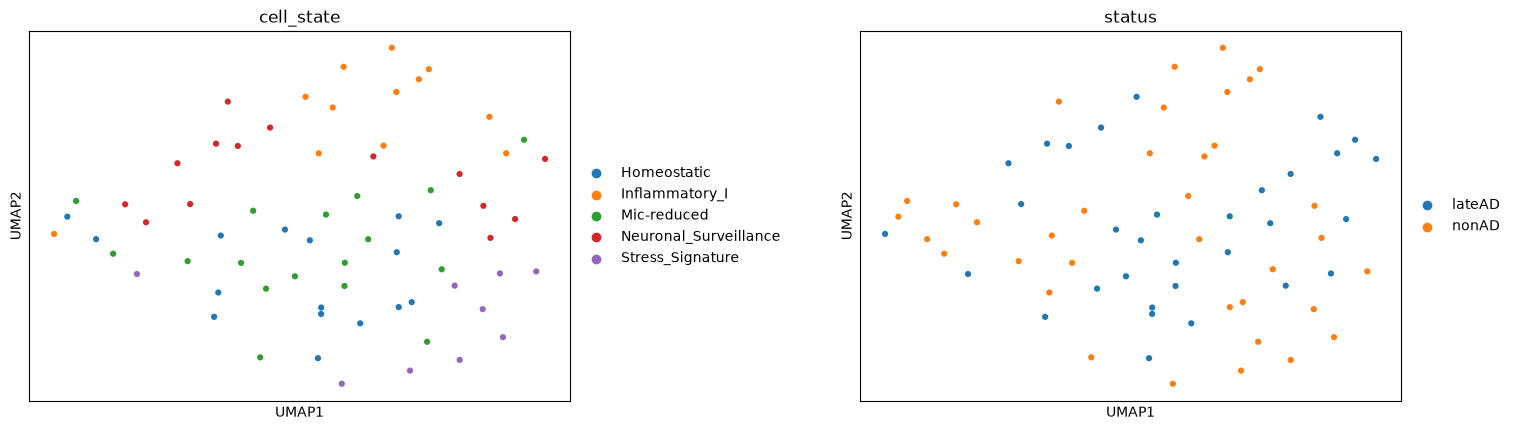

In [8]:
emb = tg.copy()
sc.pp.pca(emb, n_comps=30)
sc.pp.neighbors(emb, n_neighbors=15)
sc.tl.umap(emb)
sc.pl.umap(emb, color=["cell_state", "status"], wspace=0.4, size=80)

## 6. Differential systems: late-AD vs non-AD, per cell state

A negative-binomial mixed model (edgePython / NEBULA-LN) tests every window position, per cell state,
with **donor as a random effect**. Significant positions are grouped into **clusters** (systems).

In [9]:
sctg.tl.differential_systems(
    tg,
    condition_key="status", case=CASE, control=CONTROL,
    donor_key="donor", group_key="cell_state",
    verbose=False,
)

rows = []
for state, ci in tg.uns["diffsystems"]["contrasts"].items():
    if "skipped" in ci:
        rows.append((state, "skipped: " + ci["skipped"], None, None, None))
    else:
        rows.append((state, "ok", ci["n_case"], ci["n_control"], ci["n_de"]))
summary = pd.DataFrame(rows, columns=["cell_state", "status_", "n_case_mc", "n_ctrl_mc", "n_de"])
summary

,cell_state,status_,n_case_mc,n_ctrl_mc,n_de
0,Homeostatic,ok,10,6,0
1,Inflammatory_I,ok,4,8,319
2,Mic-reduced,ok,7,10,188
3,Neuronal_Surveillance,ok,8,6,0
4,Stress_Signature,ok,3,6,1054


### Adjusting for covariates

Because the effect comes from a **model**, we can adjust the case–control contrast for confounders —
something the original transcriptogram could not do. The reported `logFC` is then the case–control
coefficient **holding the covariates fixed**. Here we add `percent.mt` (a metacell-level technical
covariate). Donor-level covariates (`msex`, `age_death`, `pmi`) are supported the same way, but on
this minimal **6-donor** subset they are constant within donor and over-parameterize the model
(competing with the donor random effect), collapsing power — at the full 425-donor scale you would
include them.

In [10]:
tg_adj = tg.copy()
sctg.tl.differential_systems(
    tg_adj,
    condition_key="status", case=CASE, control=CONTROL,
    donor_key="donor", group_key="cell_state",
    covariates=["percent.mt"], verbose=False,
)
comp = []
for st, ci in tg.uns["diffsystems"]["contrasts"].items():
    cj = tg_adj.uns["diffsystems"]["contrasts"][st]
    if "skipped" in ci or "skipped" in cj:
        continue
    comp.append((st, ci["n_de"], cj["n_de"]))
pd.DataFrame(comp, columns=["cell_state", "n_de (unadjusted)", "n_de (+percent.mt)"])

,cell_state,n_de (unadjusted),n_de (+percent.mt)
0,Homeostatic,0,0
1,Inflammatory_I,319,346
2,Mic-reduced,188,9
3,Neuronal_Surveillance,0,0
4,Stress_Signature,1054,1021


### Pick a well-powered focus state

We highlight the state with the most differential positions **among those with ≥2 donors in both
groups** (so the random effect is identifiable).

In [11]:
donor_bal = mc.obs.groupby(["cell_state", "status"], observed=True)["donor"].nunique().unstack()
contrasts = tg.uns["diffsystems"]["contrasts"]
well_powered = [
    s for s, ci in contrasts.items()
    if "skipped" not in ci and ci["n_de"] > 0
    and donor_bal.loc[s, CASE] >= 2 and donor_bal.loc[s, CONTROL] >= 2
]
FOCUS = max(well_powered, key=lambda s: contrasts[s]["n_de"])
print("focus state:", FOCUS, "| n_de =", contrasts[FOCUS]["n_de"],
      "| clusters =", contrasts[FOCUS]["n_clusters"])
print("donor balance:\n", donor_bal.loc[FOCUS])

focus state: Inflammatory_I | n_de = 319 | clusters = 10
donor balance:
 status
lateAD    4
nonAD     2
Name: Inflammatory_I, dtype: int64


In [12]:
de = tg.varm[f"diffsystems_{FOCUS}"].copy()
de["protein"] = tg.var["protein"].values
print("cluster intervals:", contrasts[FOCUS]["clusters"][:10])
de[de["is_de"]].sort_values("logFC", ascending=False).head(10)

cluster intervals: [(949, 1124), (1357, 1662), (3858, 4152), (4641, 4880), (6287, 6499), (7456, 7785), (9022, 9202), (9489, 9837), (10451, 10663), (11033, 11358)]


,logFC,pValue,pAdj,tested,converged,is_de,cluster,protein
10532,0.210327,0.000176,0.012325,True,True,True,9,9606.ENSP00000384364
10531,0.210327,0.000176,0.012325,True,True,True,9,9606.ENSP00000354416
10533,0.185089,0.000504,0.026595,True,True,True,9,9606.ENSP00000241256
10534,0.184837,0.000467,0.024952,True,True,True,9,9606.ENSP00000267017
10536,0.166358,0.001133,0.046976,True,True,True,9,9606.ENSP00000323516
10535,0.166358,0.001133,0.046976,True,True,True,9,9606.ENSP00000437737
10537,0.166358,0.001133,0.046976,True,True,True,9,9606.ENSP00000359682
10538,0.166358,0.001133,0.046976,True,True,True,9,9606.ENSP00000337128
10542,0.165440,0.001219,0.048733,True,True,True,9,9606.ENSP00000321106
10541,0.165143,0.001236,0.048790,True,True,True,9,9606.ENSP00000379472


## 7. Attach gene symbols to positions (for enrichment / labels)

Reverse the dictionary to give each ordered protein a symbol.

In [13]:
prot2sym = dictionary.drop_duplicates("protein").set_index("protein")["identifier"]
bare = tg.var["protein"].str.replace(r"^\d+\.", "", regex=True)
tg.var["symbol"] = bare.map(prot2sym).fillna("").values
print("positions with a symbol:", int((tg.var['symbol'] != '').sum()), "/", tg.n_vars)

positions with a symbol: 11618 / 12396


## 8. logFC along the ordering

The per-position **model `logFC`** (case vs control, log2) — the *same* quantity the significance
shading is derived from (TMM-normalized, donor-adjusted), so peaks/valleys and shaded clusters
correspond, and significant positions are marked. This is the single-cell-appropriate view: it is a
donor-aware model estimate, not an average over (unequal, pseudoreplicated) metacells.

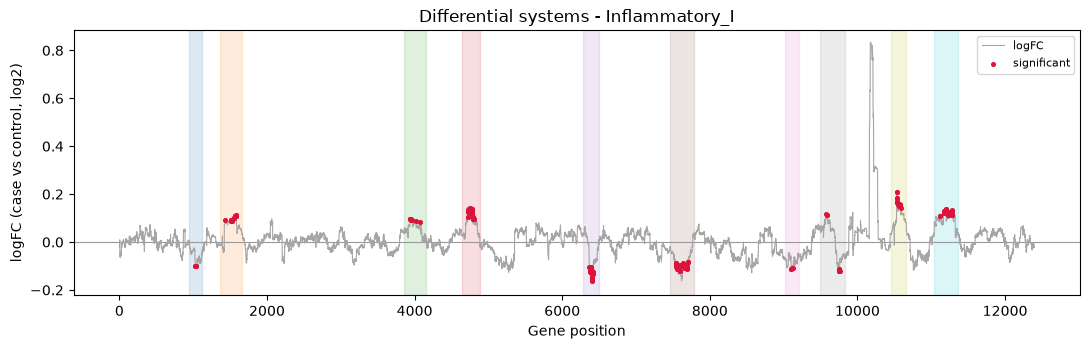

In [14]:
ax = pl.difference_of_means(tg, contrast=FOCUS, values="logFC")
ax.figure.set_size_inches(11, 3.6)
plt.tight_layout(); plt.show()

## 9. GO enrichment of the clusters

Over-representation (GSEApy / Enrichr) of GO Biological Process terms in each cluster of the focus
state, using the mapped symbols and the ordering as background. (Requires network access to Enrichr.)

In [15]:
GO_LIB = "GO_Biological_Process_2023"
# Only the (networked) Enrichr call is wrapped; display never nulls the result.
try:
    sctg.tl.cluster_enrichment(
        tg, GO_LIB, contrasts=[FOCUS], online=True,
        gene_symbol_col="symbol", strip_prefix=False, p_value=0.05,
    )
except Exception as e:
    print("enrichment skipped (Enrichr/network issue):", e)

enr = tg.uns.get("enrichment", {}).get(FOCUS)
if enr is not None and len(enr):
    cols = [c for c in ["cluster", "term", "overlap", "pAdj", "genes"] if c in enr.columns]
    display(enr.sort_values(["cluster", "pAdj"]).groupby("cluster").head(2)[cols])
else:
    print("no terms passed the threshold for", FOCUS)

,cluster,term,pAdj,genes
0,1,Protein Glycosylation (GO:0006486),2.165945e-45,GALNT14;ST6GALNAC1;GALNT13;GALNT16;GALNT18;GAL...
1,1,Protein O-linked Glycosylation (GO:0006493),2.319043e-43,GALNT14;GALNT13;GALNT16;GALNT18;GALNT17;FUT3;F...
57,2,tRNA Aminoacylation For Protein Translation (G...,7.233376e-11,RARS2;AARS2;SARS2;MARS2;IARS2;TARS2;FARSA;HARS...
58,2,Extracellular Structure Organization (GO:0043062),7.233376e-11,TEX14;ADAMTS12;ADAMTS10;THSD4;ADAMTS20;ADAMTS1...
84,3,Regulation Of Transcription By RNA Polymerase ...,5.485134e-69,ATF2;CCNK;CCNT2;CCNT1;MAML1;ARID4A;MBD3L2;RBPJ...
85,3,Transcription By RNA Polymerase II (GO:0006366),3.535379e-61,CCNK;CCNT2;THRB;CCNT1;ICE1;ELL;THRA;CCNH;ICE2;...
329,4,Nuclear Transport (GO:0051169),6.704070e-29,NDC1;NUP214;RANBP2;NUP205;POM121;NPM1;NUP107;S...
330,4,Nucleocytoplasmic Transport (GO:0006913),5.492777e-27,NDC1;NUP214;RANBP2;NUP205;POM121;NPM1;NUP107;S...
460,5,Interferon-Mediated Signaling Pathway (GO:0140...,1.892677e-24,IFITM3;IFNAR2;IFNA4;IFNA7;IFITM2;IFNA6;IFNA14;...
461,5,Cellular Response To Type I Interferon (GO:007...,6.397868e-24,IFITM3;IFNAR2;IFNA4;IFNA7;IFITM2;IFNA6;IFNA14;...


## 10. GO-term rate along the ordering

For the top enriched terms, the fraction of proteins within each sliding window annotated to the term —
reusing the same boxcar on a 0/1 annotation vector — with clusters shaded.

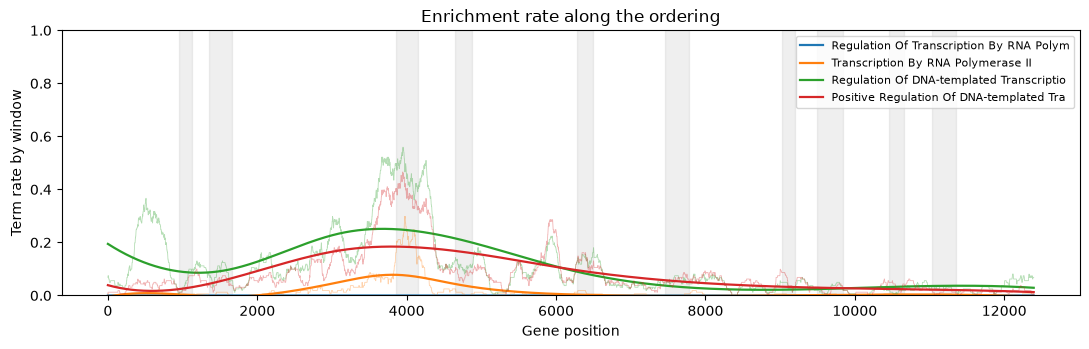

In [16]:
try:
    import gseapy
    enr = tg.uns.get("enrichment", {}).get(FOCUS)
    if enr is not None and len(enr):
        go_lib = gseapy.get_library(name=GO_LIB, organism="human")
        top_terms = list(enr.sort_values("pAdj")["term"].drop_duplicates().head(4))
        ax = pl.enrichment_rate(
            tg, go_lib, top_terms, gene_symbol_col="symbol",
            contrast=FOCUS, term_labels={t: t.split(" (GO")[0][:40] for t in top_terms},
        )
        ax.figure.set_size_inches(11, 3.6)
        plt.tight_layout(); plt.show()
    else:
        print("no enriched terms to plot")
except Exception as e:
    print("enrichment-rate plot skipped:", e)

## 11. Save results

Persist the analysed transcriptogram (embedding, window counts, per-state DE tables, clusters,
enrichment) and the DE / enrichment tables.

In [17]:
tg.write_h5ad(OBJ / "tg_analysis.h5ad")
for state, ci in tg.uns["diffsystems"]["contrasts"].items():
    if "skipped" in ci:
        continue
    tg.varm[f"diffsystems_{state}"].assign(protein=tg.var["protein"].values,
                                           symbol=tg.var["symbol"].values) \
        .to_csv(RES / f"diffsystems_{state}.csv")
if tg.uns.get("enrichment", {}).get(FOCUS) is not None:
    tg.uns["enrichment"][FOCUS].to_csv(RES / f"enrichment_{FOCUS}.csv", index=False)
print("saved to", OBJ / "tg_analysis.h5ad", "and", RES)

saved to /dora_zfs/home/deso14_OSUMC/projects/sctranscriptogram/testing/objects/tg_analysis.h5ad and /dora_zfs/home/deso14_OSUMC/projects/sctranscriptogram/testing/results
